In [1]:
# ============================================================
# STAGE 3 - CELL 1: Import Libraries and Load Cleaned Data
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

# Plot styling
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size']      = 11
plt.rcParams['axes.grid']      = True
plt.rcParams['grid.alpha']     = 0.3
sns.set_theme(style="whitegrid")

# ── Paths ─────────────────────────────────────────────────────
PROJECT_ROOT  = "C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project"
RESULTS_DIR   = os.path.join(PROJECT_ROOT, "results")
PLOTS_DIR     = os.path.join(PROJECT_ROOT, "plots")
MODELS_DIR    = os.path.join(PROJECT_ROOT, "models")

# ── Load the three cleaned datasets saved in Stage 2 ──────────
df_kano = pd.read_csv(
    os.path.join(RESULTS_DIR, 'kano_cleaned.csv'),
    index_col='Datetime', parse_dates=True)

df_maiduguri = pd.read_csv(
    os.path.join(RESULTS_DIR, 'maiduguri_cleaned.csv'),
    index_col='Datetime', parse_dates=True)

df_abuja = pd.read_csv(
    os.path.join(RESULTS_DIR, 'abuja_cleaned.csv'),
    index_col='Datetime', parse_dates=True)

print("="*55)
print("CLEANED DATASETS LOADED SUCCESSFULLY")
print("="*55)
for name, df in [('Kano', df_kano),
                  ('Maiduguri', df_maiduguri),
                  ('Abuja', df_abuja)]:
    print(f"{name}: {len(df):,} rows × "
          f"{df.shape[1]} columns")
    print(f"  Columns: {list(df.columns)}")
    print(f"  Range  : {df.index[0]} → {df.index[-1]}\n")

CLEANED DATASETS LOADED SUCCESSFULLY
Kano: 70,128 rows × 8 columns
  Columns: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'City', 'Season']
  Range  : 2016-01-01 00:00:00 → 2023-12-31 23:00:00

Maiduguri: 70,128 rows × 8 columns
  Columns: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'City', 'Season']
  Range  : 2016-01-01 00:00:00 → 2023-12-31 23:00:00

Abuja: 70,128 rows × 8 columns
  Columns: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'City', 'Season']
  Range  : 2016-01-01 00:00:00 → 2023-12-31 23:00:00



In [2]:
# ============================================================
# STAGE 3 - CELL 2: Create Target Variable — PV Power Output
# ============================================================

# Your datasets currently only contain meteorological inputs.
# We need to compute the PV power output that the model
# will learn to predict.
#
# We use a standard PV performance model:
#
#   Power (kW) = GHI × Panel_Area × Efficiency × Temperature_Factor
#
# Parameters chosen to represent a realistic 1 MW solar farm:
#   Panel Area     = 5000 m² (total area of panels)
#   Base Efficiency= 0.20 (20% — standard monocrystalline panels)
#   Temp Coefficient= -0.004 per °C above 25°C
#   (panels lose 0.4% efficiency per degree above 25°C)
#   System Losses  = 0.80 (accounts for inverter, wiring etc.)

PANEL_AREA      = 5000     # m²
BASE_EFFICIENCY = 0.20     # 20% base conversion efficiency
TEMP_COEFF      = -0.004   # efficiency loss per °C above 25°C
SYSTEM_LOSSES   = 0.80     # 80% system efficiency factor
REFERENCE_TEMP  = 25.0     # Reference temperature in °C

def compute_pv_power(df):
    """
    Computes hourly PV power output in kilowatts using a
    standard temperature-corrected PV performance model.

    The temperature correction is critical for Northern Nigeria
    because panel efficiency drops significantly during the
    extreme heat of harmattan season in Kano and Maiduguri.
    """

    # Temperature correction factor
    # When temperature = 25°C, factor = 1.0 (no correction)
    # When temperature = 45°C, factor = 1 + (-0.004 × 20) = 0.92
    # Meaning efficiency drops to 92% of baseline at 45°C
    temp_factor = 1 + TEMP_COEFF * (df['Temperature'] - REFERENCE_TEMP)

    # Ensure temperature factor never goes below 0.5
    # (a physical lower bound — panels do not become
    # completely useless even in extreme heat)
    temp_factor = temp_factor.clip(lower=0.5)

    # PV Power formula
    # GHI is in W/m² so we divide by 1000 to convert to kW/m²
    power_kw = (df['GHI'] / 1000) * PANEL_AREA * \
                BASE_EFFICIENCY * temp_factor * SYSTEM_LOSSES

    return power_kw.round(4)


# Apply to all three cities
df_kano['PV_Power']      = compute_pv_power(df_kano)
df_maiduguri['PV_Power'] = compute_pv_power(df_maiduguri)
df_abuja['PV_Power']     = compute_pv_power(df_abuja)

# Verify the results
print("="*55)
print("PV POWER OUTPUT — SUMMARY STATISTICS")
print("="*55)
for name, df in [('Kano', df_kano),
                  ('Maiduguri', df_maiduguri),
                  ('Abuja', df_abuja)]:
    day = df[df['GHI'] > 0]['PV_Power']
    print(f"\n{name} (daytime only):")
    print(f"  Min power : {day.min():.2f} kW")
    print(f"  Max power : {day.max():.2f} kW")
    print(f"  Mean power: {day.mean():.2f} kW")
    print(f"  At peak GHI of ~850 W/m² and 30°C: "
          f"{(850/1000)*5000*0.20*(1+(-0.004*(30-25)))*0.80:.1f} kW")

PV POWER OUTPUT — SUMMARY STATISTICS

Kano (daytime only):
  Min power : 0.77 kW
  Max power : 852.37 kW
  Mean power: 372.36 kW
  At peak GHI of ~850 W/m² and 30°C: 666.4 kW

Maiduguri (daytime only):
  Min power : 0.31 kW
  Max power : 831.37 kW
  Mean power: 371.62 kW
  At peak GHI of ~850 W/m² and 30°C: 666.4 kW

Abuja (daytime only):
  Min power : 0.81 kW
  Max power : 813.65 kW
  Mean power: 330.81 kW
  At peak GHI of ~850 W/m² and 30°C: 666.4 kW


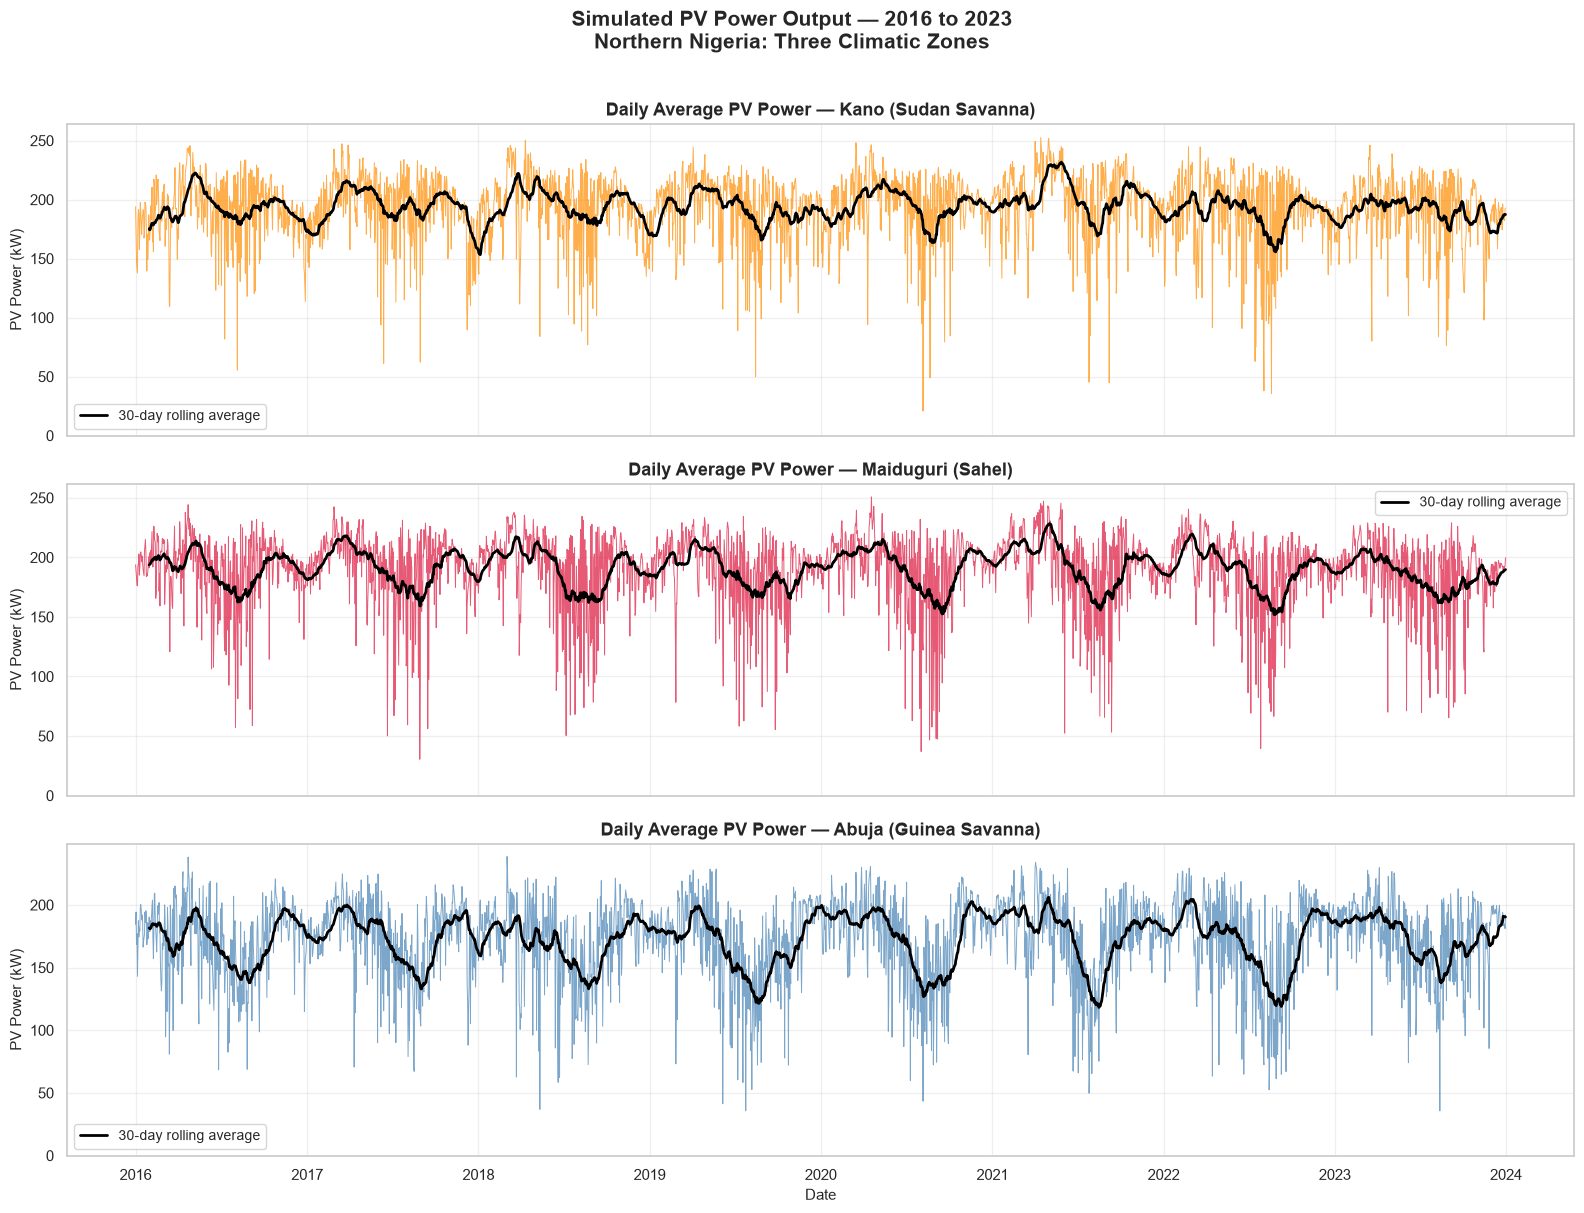

✅ Plot saved to: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\PV_Power_timeseries.png


In [3]:
# ============================================================
# STAGE 3 - CELL 3: Visualise PV Power to Validate the Model
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

cities_data = [
    (df_kano,      'Kano (Sudan Savanna)',  'darkorange'),
    (df_maiduguri, 'Maiduguri (Sahel)',      'crimson'),
    (df_abuja,     'Abuja (Guinea Savanna)', 'steelblue')
]

for ax, (df, label, color) in zip(axes, cities_data):
    daily_power = df['PV_Power'].resample('D').mean()
    rolling     = daily_power.rolling(window=30).mean()

    ax.plot(daily_power.index, daily_power.values,
            color=color, linewidth=0.7, alpha=0.7)
    ax.plot(rolling.index, rolling.values,
            color='black', linewidth=2,
            label='30-day rolling average')

    ax.set_title(f'Daily Average PV Power — {label}',
                 fontsize=13, fontweight='bold')
    ax.set_ylabel('PV Power (kW)', fontsize=11)
    ax.legend(fontsize=10)
    ax.set_ylim(0, None)

axes[-1].set_xlabel('Date', fontsize=11)
fig.suptitle('Simulated PV Power Output — 2016 to 2023\n'
             'Northern Nigeria: Three Climatic Zones',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()

save_path = os.path.join(PLOTS_DIR, 'PV_Power_timeseries.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Plot saved to: {save_path}")

In [4]:
# ============================================================
# STAGE 3 - CELL 4: Engineer Temporal Features
# ============================================================

# Temporal features give the model explicit knowledge of
# WHERE in time each observation sits.
# Without these, the model sees raw numbers but does not
# know "this is 6am" or "this is July" or "this is harmattan"
#
# We use SINE and COSINE encoding for cyclical features
# like hour and month. This is important because:
# Hour 23 and Hour 0 are actually very close in time (1 hour apart)
# but numerically they are far apart (23 vs 0).
# Sine/cosine encoding wraps these numbers into a circle
# so the model understands their true cyclical proximity.

def engineer_temporal_features(df):
    """
    Creates temporal features from the DateTime index.
    All features are derived purely from the timestamp
    and add calendar and cyclical knowledge to the model.
    """

    # ── Basic temporal features ───────────────────────────
    df['Hour']       = df.index.hour
    df['Month']      = df.index.month
    df['DayOfYear']  = df.index.dayofyear
    df['DayOfWeek']  = df.index.dayofweek  # 0=Monday 6=Sunday
    df['WeekOfYear'] = df.index.isocalendar().week.astype(int)

    # ── Cyclical encoding for Hour (0 to 23) ─────────────
    # Converts hour into two features that form a circle
    # so Hour 0 and Hour 23 are recognised as neighbours
    df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
    df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)

    # ── Cyclical encoding for Month (1 to 12) ────────────
    # December and January are neighbours on the calendar
    # Sine/cosine encoding captures this circular relationship
    df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
    df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

    # ── Cyclical encoding for Day of Year (1 to 365) ─────
    df['DayOfYear_sin'] = np.sin(2 * np.pi * df['DayOfYear'] / 365)
    df['DayOfYear_cos'] = np.cos(2 * np.pi * df['DayOfYear'] / 365)

    # ── Season encoding ───────────────────────────────────
    # Convert the Season text column to numbers
    # Harmattan=0, Monsoon=1, Transition=2
    season_map = {'Harmattan': 0, 'Monsoon': 1, 'Transition': 2}
    df['Season_encoded'] = df['Season'].map(season_map)

    # ── Daytime flag ──────────────────────────────────────
    # Binary indicator: 1 if sun is up (GHI > 0), 0 if night
    # Helps model distinguish daytime prediction task from
    # nighttime (where answer is always 0)
    df['Is_Daytime'] = (df['GHI'] > 0).astype(int)

    # ── Lag features ─────────────────────────────────────
    # Previous hour's PV power — autoregressive feature
    # The single most predictive feature for next-hour power
    # is the current hour's power (solar patterns are smooth)
    df['PV_Power_Lag1']  = df['PV_Power'].shift(1)

    # 24 hours ago — same hour yesterday
    # Captures the daily cyclical pattern
    df['PV_Power_Lag24'] = df['PV_Power'].shift(24)

    # Previous hour GHI — irradiance one hour ago
    df['GHI_Lag1']       = df['GHI'].shift(1)

    return df


# Apply to all three cities
df_kano      = engineer_temporal_features(df_kano)
df_maiduguri = engineer_temporal_features(df_maiduguri)
df_abuja     = engineer_temporal_features(df_abuja)

# Check new columns
print("="*55)
print("FEATURES AFTER ENGINEERING — KANO")
print("="*55)
print(f"Total columns: {df_kano.shape[1]}")
print(f"\nAll column names:")
for col in df_kano.columns:
    print(f"  - {col}")
print(f"\nSample row (daytime):")
print(df_kano[df_kano['Is_Daytime']==1].iloc[0])

FEATURES AFTER ENGINEERING — KANO
Total columns: 25

All column names:
  - GHI
  - DHI
  - Clearness
  - Temperature
  - Humidity
  - WindSpeed
  - City
  - Season
  - PV_Power
  - Hour
  - Month
  - DayOfYear
  - DayOfWeek
  - WeekOfYear
  - Hour_sin
  - Hour_cos
  - Month_sin
  - Month_cos
  - DayOfYear_sin
  - DayOfYear_cos
  - Season_encoded
  - Is_Daytime
  - PV_Power_Lag1
  - PV_Power_Lag24
  - GHI_Lag1

Sample row (daytime):
GHI                   86.53
DHI                   71.42
Clearness               0.4
Temperature           10.09
Humidity              44.62
WindSpeed               2.7
City                   Kano
Season            Harmattan
PV_Power            73.3525
Hour                      7
Month                     1
DayOfYear                 1
DayOfWeek                 4
WeekOfYear               53
Hour_sin           0.965926
Hour_cos          -0.258819
Month_sin               0.5
Month_cos          0.866025
DayOfYear_sin      0.017213
DayOfYear_cos      0.999852
Seas

In [5]:
# ============================================================
# STAGE 3 - CELL 5: Drop Rows With NaN From Lag Features
# ============================================================

# When we create lag features using .shift(1) and .shift(24),
# the first 1 row and first 24 rows cannot have lag values
# because there is no "previous hour" data for them.
# Pandas fills these with NaN (Not a Number).
# We must remove these rows before training.

print("="*55)
print("NaN CHECK BEFORE DROPPING")
print("="*55)

for name, df in [('Kano', df_kano),
                  ('Maiduguri', df_maiduguri),
                  ('Abuja', df_abuja)]:
    nan_count = df.isnull().sum().sum()
    print(f"{name}: {nan_count} NaN values")

# Drop NaN rows — only the first 24 rows per city are affected
# This is negligible compared to 70,128 total rows
df_kano      = df_kano.dropna()
df_maiduguri = df_maiduguri.dropna()
df_abuja     = df_abuja.dropna()

print("\n" + "="*55)
print("NaN CHECK AFTER DROPPING")
print("="*55)

for name, df in [('Kano', df_kano),
                  ('Maiduguri', df_maiduguri),
                  ('Abuja', df_abuja)]:
    nan_count = df.isnull().sum().sum()
    print(f"{name}: {nan_count} NaN values | "
          f"{len(df):,} rows remaining")

NaN CHECK BEFORE DROPPING
Kano: 26 NaN values
Maiduguri: 26 NaN values
Abuja: 26 NaN values

NaN CHECK AFTER DROPPING
Kano: 0 NaN values | 70,104 rows remaining
Maiduguri: 0 NaN values | 70,104 rows remaining
Abuja: 0 NaN values | 70,104 rows remaining


In [6]:
# ============================================================
# STAGE 3 - CELL 6: Define the Final Feature Set
# ============================================================

# These are the exact columns that will be fed into
# the CNN-biLSTM model as input features (X)
# The order here matters — it defines the order of
# features in the model's input tensor

INPUT_FEATURES = [
    # ── Solar radiation features ──────────────────────────
    'GHI',              # Global Horizontal Irradiance
    'DHI',              # Diffuse Horizontal Irradiance
    'Clearness',        # Sky clearness index

    # ── Meteorological features ───────────────────────────
    'Temperature',      # Ambient temperature
    'Humidity',         # Relative humidity
    'WindSpeed',        # Wind speed

    # ── Cyclical temporal features ────────────────────────
    'Hour_sin',         # Hour encoded as sine
    'Hour_cos',         # Hour encoded as cosine
    'Month_sin',        # Month encoded as sine
    'Month_cos',        # Month encoded as cosine
    'DayOfYear_sin',    # Day of year sine
    'DayOfYear_cos',    # Day of year cosine

    # ── Categorical temporal features ─────────────────────
    'Season_encoded',   # Harmattan=0, Monsoon=1, Transition=2
    'Is_Daytime',       # 1 if sun is up, 0 if night

    # ── Autoregressive lag features ───────────────────────
    'PV_Power_Lag1',    # PV power one hour ago
    'PV_Power_Lag24',   # PV power 24 hours ago
    'GHI_Lag1',         # GHI one hour ago
]

# The target variable — what the model predicts
TARGET = 'PV_Power'

print("="*55)
print("FINAL FEATURE SET")
print("="*55)
print(f"\nNumber of input features: {len(INPUT_FEATURES)}")
print(f"\nInput features (X):")
for i, feat in enumerate(INPUT_FEATURES, 1):
    print(f"  {i:2}. {feat}")
print(f"\nTarget variable (y): {TARGET}")

FINAL FEATURE SET

Number of input features: 17

Input features (X):
   1. GHI
   2. DHI
   3. Clearness
   4. Temperature
   5. Humidity
   6. WindSpeed
   7. Hour_sin
   8. Hour_cos
   9. Month_sin
  10. Month_cos
  11. DayOfYear_sin
  12. DayOfYear_cos
  13. Season_encoded
  14. Is_Daytime
  15. PV_Power_Lag1
  16. PV_Power_Lag24
  17. GHI_Lag1

Target variable (y): PV_Power


In [7]:
# ============================================================
# STAGE 3 - CELL 7: Chronological Train/Validation/Test Split
# ============================================================

# We split the data by TIME not randomly.
# NEVER shuffle time-series data before splitting.
# Shuffling would allow future data to leak into training
# producing artificially inflated accuracy scores.
#
# Split strategy (matches your proposal exactly):
#   Training   : 2016 to 2021 (6 years = 75%)
#   Validation : 2022         (1 year  = 12.5%)
#   Test       : 2023         (1 year  = 12.5%)

def split_data(df):
    """
    Splits a DataFrame chronologically into
    training, validation, and test sets.
    """
    train = df[df.index.year <= 2021]
    val   = df[df.index.year == 2022]
    test  = df[df.index.year == 2023]
    return train, val, test


# Split all three cities
train_kano, val_kano, test_kano             = split_data(df_kano)
train_maid, val_maid, test_maid             = split_data(df_maiduguri)
train_abuja, val_abuja, test_abuja          = split_data(df_abuja)

print("="*55)
print("DATA SPLIT SUMMARY")
print("="*55)

for city, train, val, test in [
    ('Kano',      train_kano,  val_kano,  test_kano),
    ('Maiduguri', train_maid,  val_maid,  test_maid),
    ('Abuja',     train_abuja, val_abuja, test_abuja)
]:
    total = len(train) + len(val) + len(test)
    print(f"\n{city}:")
    print(f"  Training   (2016-2021): {len(train):,} rows "
          f"({len(train)/total*100:.1f}%)")
    print(f"  Validation (2022)     : {len(val):,} rows "
          f"({len(val)/total*100:.1f}%)")
    print(f"  Test       (2023)     : {len(test):,} rows "
          f"({len(test)/total*100:.1f}%)")
    print(f"  Total                 : {total:,} rows")

DATA SPLIT SUMMARY

Kano:
  Training   (2016-2021): 52,584 rows (75.0%)
  Validation (2022)     : 8,760 rows (12.5%)
  Test       (2023)     : 8,760 rows (12.5%)
  Total                 : 70,104 rows

Maiduguri:
  Training   (2016-2021): 52,584 rows (75.0%)
  Validation (2022)     : 8,760 rows (12.5%)
  Test       (2023)     : 8,760 rows (12.5%)
  Total                 : 70,104 rows

Abuja:
  Training   (2016-2021): 52,584 rows (75.0%)
  Validation (2022)     : 8,760 rows (12.5%)
  Test       (2023)     : 8,760 rows (12.5%)
  Total                 : 70,104 rows


In [8]:
# ============================================================
# STAGE 3 - CELL 8: MinMax Normalisation
# ============================================================

# Normalisation scales all features to the range [0, 1]
# This is essential because:
# GHI can reach 900 W/m² while Hour_sin is between -1 and +1
# Without scaling the model would pay far more attention to
# GHI simply because its numbers are larger — not because
# it is more important.
#
# CRITICAL RULE: Fit the scaler ONLY on training data.
# Then apply the same fitted scaler to validation and test.
# Fitting on all data would leak test statistics into
# training — a form of data leakage that inflates results.

def normalise_city(train, val, test, feature_cols, target_col):
    """
    Fits MinMaxScaler on training data only.
    Applies the same scaler to val and test.
    Returns normalised arrays and the fitted scalers.
    """

    # ── Feature scaler ────────────────────────────────────
    feature_scaler = MinMaxScaler(feature_range=(0, 1))

    # Fit on training features only
    train_X = feature_scaler.fit_transform(
        train[feature_cols].values)

    # Apply (transform only, no fitting) to val and test
    val_X   = feature_scaler.transform(val[feature_cols].values)
    test_X  = feature_scaler.transform(test[feature_cols].values)

    # ── Target scaler ─────────────────────────────────────
    target_scaler = MinMaxScaler(feature_range=(0, 1))

    # Reshape to 2D for scaler (scaler expects 2D array)
    train_y = target_scaler.fit_transform(
        train[[target_col]].values)
    val_y   = target_scaler.transform(val[[target_col]].values)
    test_y  = target_scaler.transform(test[[target_col]].values)

    # Flatten back to 1D arrays
    train_y = train_y.flatten()
    val_y   = val_y.flatten()
    test_y  = test_y.flatten()

    return (train_X, val_X, test_X,
            train_y, val_y, test_y,
            feature_scaler, target_scaler)


# Apply normalisation to all three cities
(X_train_kano, X_val_kano, X_test_kano,
 y_train_kano, y_val_kano, y_test_kano,
 feat_scaler_kano, tgt_scaler_kano) = normalise_city(
    train_kano, val_kano, test_kano,
    INPUT_FEATURES, TARGET)

(X_train_maid, X_val_maid, X_test_maid,
 y_train_maid, y_val_maid, y_test_maid,
 feat_scaler_maid, tgt_scaler_maid) = normalise_city(
    train_maid, val_maid, test_maid,
    INPUT_FEATURES, TARGET)

(X_train_abuja, X_val_abuja, X_test_abuja,
 y_train_abuja, y_val_abuja, y_test_abuja,
 feat_scaler_abuja, tgt_scaler_abuja) = normalise_city(
    train_abuja, val_abuja, test_abuja,
    INPUT_FEATURES, TARGET)

print("="*55)
print("NORMALISATION COMPLETE")
print("="*55)
print(f"\nFeature array shapes:")
print(f"  Kano Train X : {X_train_kano.shape}")
print(f"  Kano Val   X : {X_val_kano.shape}")
print(f"  Kano Test  X : {X_test_kano.shape}")
print(f"\nTarget array shapes:")
print(f"  Kano Train y : {y_train_kano.shape}")
print(f"\nValue range check (should be 0.0 to 1.0):")
print(f"  X_train_kano min: {X_train_kano.min():.4f}")
print(f"  X_train_kano max: {X_train_kano.max():.4f}")
print(f"  y_train_kano min: {y_train_kano.min():.4f}")
print(f"  y_train_kano max: {y_train_kano.max():.4f}")

NORMALISATION COMPLETE

Feature array shapes:
  Kano Train X : (52584, 17)
  Kano Val   X : (8760, 17)
  Kano Test  X : (8760, 17)

Target array shapes:
  Kano Train y : (52584,)

Value range check (should be 0.0 to 1.0):
  X_train_kano min: 0.0000
  X_train_kano max: 1.0000
  y_train_kano min: 0.0000
  y_train_kano max: 1.0000


In [9]:
# ============================================================
# STAGE 3 - CELL 9: Create Sliding Window Sequences
# ============================================================

# The CNN-biLSTM does not receive individual hourly rows.
# It receives SEQUENCES — windows of consecutive hours.
#
# With a window size of 24:
# Input  (X): hours t-23, t-22, ... t-1, t  (last 24 hours)
# Output (y): hour t+1  (next hour's power)
#
# This creates a 3D array of shape:
# (number_of_sequences, window_size, number_of_features)
# e.g. (52000, 24, 17)
#
# This is exactly the shape the CNN expects as input.

WINDOW_SIZE = 24  # 24 hours of history to predict 1 hour ahead

def create_sequences(X, y, window_size):
    """
    Converts flat 2D arrays (rows × features) into
    3D sequence arrays (sequences × timesteps × features)
    suitable for CNN-biLSTM input.

    For each position t in the data:
    - X_seq[t] = rows from t to t+window_size-1 (the window)
    - y_seq[t] = y value at t+window_size (the next hour)
    """

    X_sequences = []
    y_sequences = []

    # Slide the window across the entire dataset
    for t in range(len(X) - window_size):
        # Extract window of 24 consecutive hours
        window = X[t : t + window_size]
        # Target is the hour immediately after the window
        target = y[t + window_size]

        X_sequences.append(window)
        y_sequences.append(target)

    return np.array(X_sequences), np.array(y_sequences)


print("Creating sequences — this may take a minute...")
print(f"Window size: {WINDOW_SIZE} hours\n")

# Create sequences for all splits and all cities
# ── Kano ──────────────────────────────────────────────────
X_seq_train_kano, y_seq_train_kano = create_sequences(
    X_train_kano, y_train_kano, WINDOW_SIZE)
X_seq_val_kano,   y_seq_val_kano   = create_sequences(
    X_val_kano,   y_val_kano,   WINDOW_SIZE)
X_seq_test_kano,  y_seq_test_kano  = create_sequences(
    X_test_kano,  y_test_kano,  WINDOW_SIZE)

# ── Maiduguri ──────────────────────────────────────────────
X_seq_train_maid, y_seq_train_maid = create_sequences(
    X_train_maid, y_train_maid, WINDOW_SIZE)
X_seq_val_maid,   y_seq_val_maid   = create_sequences(
    X_val_maid,   y_val_maid,   WINDOW_SIZE)
X_seq_test_maid,  y_seq_test_maid  = create_sequences(
    X_test_maid,  y_test_maid,  WINDOW_SIZE)

# ── Abuja ──────────────────────────────────────────────────
X_seq_train_abuja, y_seq_train_abuja = create_sequences(
    X_train_abuja, y_train_abuja, WINDOW_SIZE)
X_seq_val_abuja,   y_seq_val_abuja   = create_sequences(
    X_val_abuja,   y_val_abuja,   WINDOW_SIZE)
X_seq_test_abuja,  y_seq_test_abuja  = create_sequences(
    X_test_abuja,  y_test_abuja,  WINDOW_SIZE)

print("="*55)
print("SEQUENCE SHAPES")
print("="*55)
print(f"\nKano:")
print(f"  Train: X={X_seq_train_kano.shape} "
      f"y={y_seq_train_kano.shape}")
print(f"  Val  : X={X_seq_val_kano.shape}   "
      f"y={y_seq_val_kano.shape}")
print(f"  Test : X={X_seq_test_kano.shape}  "
      f"y={y_seq_test_kano.shape}")

print(f"\nMaiduguri:")
print(f"  Train: X={X_seq_train_maid.shape} "
      f"y={y_seq_train_maid.shape}")

print(f"\nAbuja:")
print(f"  Train: X={X_seq_train_abuja.shape} "
      f"y={y_seq_train_abuja.shape}")

print(f"\nShape meaning: "
      f"(sequences, timesteps, features) = "
      f"(N, {WINDOW_SIZE}, {len(INPUT_FEATURES)})")

Creating sequences — this may take a minute...
Window size: 24 hours

SEQUENCE SHAPES

Kano:
  Train: X=(52560, 24, 17) y=(52560,)
  Val  : X=(8736, 24, 17)   y=(8736,)
  Test : X=(8736, 24, 17)  y=(8736,)

Maiduguri:
  Train: X=(52560, 24, 17) y=(52560,)

Abuja:
  Train: X=(52560, 24, 17) y=(52560,)

Shape meaning: (sequences, timesteps, features) = (N, 24, 17)


In [10]:
# ============================================================
# STAGE 3 - CELL 10: Save All Processed Data for Stage 4
# ============================================================

# Save the sequence arrays as numpy .npy files
# These can be loaded instantly in Stage 4 without
# repeating all the feature engineering and sequencing

save_dir = os.path.join(RESULTS_DIR, 'sequences')
os.makedirs(save_dir, exist_ok=True)

# ── Save Kano sequences ────────────────────────────────────
np.save(os.path.join(save_dir, 'X_train_kano.npy'),
        X_seq_train_kano)
np.save(os.path.join(save_dir, 'y_train_kano.npy'),
        y_seq_train_kano)
np.save(os.path.join(save_dir, 'X_val_kano.npy'),
        X_seq_val_kano)
np.save(os.path.join(save_dir, 'y_val_kano.npy'),
        y_seq_val_kano)
np.save(os.path.join(save_dir, 'X_test_kano.npy'),
        X_seq_test_kano)
np.save(os.path.join(save_dir, 'y_test_kano.npy'),
        y_seq_test_kano)

# ── Save Maiduguri sequences ───────────────────────────────
np.save(os.path.join(save_dir, 'X_train_maid.npy'),
        X_seq_train_maid)
np.save(os.path.join(save_dir, 'y_train_maid.npy'),
        y_seq_train_maid)
np.save(os.path.join(save_dir, 'X_val_maid.npy'),
        X_seq_val_maid)
np.save(os.path.join(save_dir, 'y_val_maid.npy'),
        y_seq_val_maid)
np.save(os.path.join(save_dir, 'X_test_maid.npy'),
        X_seq_test_maid)
np.save(os.path.join(save_dir, 'y_test_maid.npy'),
        y_seq_test_maid)

# ── Save Abuja sequences ───────────────────────────────────
np.save(os.path.join(save_dir, 'X_train_abuja.npy'),
        X_seq_train_abuja)
np.save(os.path.join(save_dir, 'y_train_abuja.npy'),
        y_seq_train_abuja)
np.save(os.path.join(save_dir, 'X_val_abuja.npy'),
        X_seq_val_abuja)
np.save(os.path.join(save_dir, 'y_val_abuja.npy'),
        y_seq_val_abuja)
np.save(os.path.join(save_dir, 'X_test_abuja.npy'),
        X_seq_test_abuja)
np.save(os.path.join(save_dir, 'y_test_abuja.npy'),
        y_seq_test_abuja)

# ── Save the scalers ──────────────────────────────────────
# We MUST save the scalers because we need them later
# to inverse-transform predictions back to real kW values
joblib.dump(feat_scaler_kano,
            os.path.join(MODELS_DIR, 'feat_scaler_kano.pkl'))
joblib.dump(tgt_scaler_kano,
            os.path.join(MODELS_DIR, 'tgt_scaler_kano.pkl'))
joblib.dump(feat_scaler_maid,
            os.path.join(MODELS_DIR, 'feat_scaler_maid.pkl'))
joblib.dump(tgt_scaler_maid,
            os.path.join(MODELS_DIR, 'tgt_scaler_maid.pkl'))
joblib.dump(feat_scaler_abuja,
            os.path.join(MODELS_DIR, 'feat_scaler_abuja.pkl'))
joblib.dump(tgt_scaler_abuja,
            os.path.join(MODELS_DIR, 'tgt_scaler_abuja.pkl'))

# ── Confirmation ──────────────────────────────────────────
print("="*55)
print("ALL SEQUENCES AND SCALERS SAVED")
print("="*55)

seq_files = os.listdir(save_dir)
print(f"\nSequence files saved ({len(seq_files)} files):")
for f in sorted(seq_files):
    size = os.path.getsize(
        os.path.join(save_dir, f)) / (1024*1024)
    print(f"  ✅ {f}  —  {size:.1f} MB")

scaler_files = [f for f in os.listdir(MODELS_DIR)
                if f.endswith('.pkl')]
print(f"\nScaler files saved ({len(scaler_files)} files):")
for f in sorted(scaler_files):
    print(f"  ✅ {f}")

ALL SEQUENCES AND SCALERS SAVED

Sequence files saved (18 files):
  ✅ X_test_abuja.npy  —  27.2 MB
  ✅ X_test_kano.npy  —  27.2 MB
  ✅ X_test_maid.npy  —  27.2 MB
  ✅ X_train_abuja.npy  —  163.6 MB
  ✅ X_train_kano.npy  —  163.6 MB
  ✅ X_train_maid.npy  —  163.6 MB
  ✅ X_val_abuja.npy  —  27.2 MB
  ✅ X_val_kano.npy  —  27.2 MB
  ✅ X_val_maid.npy  —  27.2 MB
  ✅ y_test_abuja.npy  —  0.1 MB
  ✅ y_test_kano.npy  —  0.1 MB
  ✅ y_test_maid.npy  —  0.1 MB
  ✅ y_train_abuja.npy  —  0.4 MB
  ✅ y_train_kano.npy  —  0.4 MB
  ✅ y_train_maid.npy  —  0.4 MB
  ✅ y_val_abuja.npy  —  0.1 MB
  ✅ y_val_kano.npy  —  0.1 MB
  ✅ y_val_maid.npy  —  0.1 MB

Scaler files saved (6 files):
  ✅ feat_scaler_abuja.pkl
  ✅ feat_scaler_kano.pkl
  ✅ feat_scaler_maid.pkl
  ✅ tgt_scaler_abuja.pkl
  ✅ tgt_scaler_kano.pkl
  ✅ tgt_scaler_maid.pkl


In [11]:
# ============================================================
# STAGE 3 - CELL 11: Stage 3 Completion Summary
# ============================================================

print("="*60)
print("STAGE 3 COMPLETE — FEATURE ENGINEERING & NORMALISATION")
print("="*60)
print()
print("✅ PV Power target variable computed")
print("   (Temperature-corrected performance model)")
print()
print("✅ Temporal features engineered:")
print("   Hour, Month, DayOfYear (raw)")
print("   Hour_sin/cos, Month_sin/cos (cyclical encoding)")
print("   DayOfYear_sin/cos (seasonal encoding)")
print("   Season_encoded, Is_Daytime (categorical)")
print()
print("✅ Lag features created:")
print("   PV_Power_Lag1  (previous hour power)")
print("   PV_Power_Lag24 (same hour yesterday)")
print("   GHI_Lag1       (previous hour irradiance)")
print()
print(f"✅ Total input features: {len(INPUT_FEATURES)}")
print()
print("✅ Chronological train/val/test split:")
print("   Training   : 2016–2021")
print("   Validation : 2022")
print("   Test       : 2023")
print()
print("✅ MinMax normalisation applied")
print("   Fitted on training data only")
print("   Applied to validation and test")
print()
print(f"✅ Sliding window sequences created")
print(f"   Window size : {WINDOW_SIZE} hours")
print(f"   Shape: (sequences × {WINDOW_SIZE} × "
      f"{len(INPUT_FEATURES)})")
print()
print("✅ All sequences saved as .npy files")
print("✅ All scalers saved as .pkl files")
print()
print(f"Kano Train sequences    : "
      f"{X_seq_train_kano.shape[0]:,}")
print(f"Maiduguri Train sequences: "
      f"{X_seq_train_maid.shape[0]:,}")
print(f"Abuja Train sequences   : "
      f"{X_seq_train_abuja.shape[0]:,}")
print()
print("NEXT → Stage 4: Build CNN-biLSTM Model")
print("="*60)

STAGE 3 COMPLETE — FEATURE ENGINEERING & NORMALISATION

✅ PV Power target variable computed
   (Temperature-corrected performance model)

✅ Temporal features engineered:
   Hour, Month, DayOfYear (raw)
   Hour_sin/cos, Month_sin/cos (cyclical encoding)
   DayOfYear_sin/cos (seasonal encoding)
   Season_encoded, Is_Daytime (categorical)

✅ Lag features created:
   PV_Power_Lag1  (previous hour power)
   PV_Power_Lag24 (same hour yesterday)
   GHI_Lag1       (previous hour irradiance)

✅ Total input features: 17

✅ Chronological train/val/test split:
   Training   : 2016–2021
   Validation : 2022
   Test       : 2023

✅ MinMax normalisation applied
   Fitted on training data only
   Applied to validation and test

✅ Sliding window sequences created
   Window size : 24 hours
   Shape: (sequences × 24 × 17)

✅ All sequences saved as .npy files
✅ All scalers saved as .pkl files

Kano Train sequences    : 52,560
Maiduguri Train sequences: 52,560
Abuja Train sequences   : 52,560

NEXT → Stage